# Buổi 5 · Tình huống 03 — Cảnh báo giao hàng trễ (Adaline)

Notebook này dùng lại bối cảnh trong [`bai-tap/buoi4-tinh-huong/03_giao_hang_tre.py`](../../bai-tap/buoi4-tinh-huong/03_giao_hang_tre.py), nhưng thay Perceptron (0/1) bằng **Adaline** học quy tắc Widrow–Hoff (LMS) với **target liên tục**.

Không có dữ liệu hoặc lời giải dựng sẵn trong notebook này. Các code cell chỉ chứa comment định hướng; bạn tự thu thập dữ liệu, xử lý, huấn luyện, đánh giá và triển khai thử.

## Bối cảnh

Một cửa hàng muốn biết đơn hàng nào có nguy cơ giao trễ để chủ động thông báo.

Feature có thể cân nhắc: khoảng cách, số đơn tài xế đang giữ, trời mưa, giờ cao điểm, thời gian chuẩn bị (mã hoá số, chuẩn hoá).

## Vì sao dùng Adaline thay Perceptron?

Thay vì chỉ 0/1 (đúng giờ / trễ), hãy coi target là **số phút trễ dự kiến** hoặc **điểm nguy cơ trễ** trong [0, 1]. Nhiều đơn sẽ có nguy cơ trung gian, không chỉ hai cực.

Nhắc lại công thức Adaline / Widrow–Hoff:

$$
\text{net} = \mathbf{w}^\top \mathbf{x} + b, \qquad e = t - \text{net}
$$

$$
\mathbf{w} \leftarrow \mathbf{w} + \eta e \mathbf{x}, \qquad b \leftarrow b + \eta e
$$

Với target là số phút trễ dự kiến, sai số MSE cho biết mức độ lệch cụ thể, chi tiết hơn so với chỉ biết đúng/sai như Perceptron.

## Nhiệm vụ suy nghĩ

1. Quyết định cách biến trời mưa và giờ cao điểm thành số (0/1 hoặc mức độ).
2. Tạo dữ liệu có cả đơn dễ đoán và đơn nằm gần ranh giới quyết định, với target liên tục.
3. Chia train/test trước khi huấn luyện Adaline.
4. Theo dõi MSE trên train và test qua các epoch; so sánh với việc chỉ đo accuracy.
5. Chọn ngưỡng cảnh báo và cân nhắc coi trọng phát hiện đơn có nguy cơ trễ cao (recall) hay tránh cảnh báo nhầm (precision).

Không có code mẫu hoặc lời giải trong notebook này. Bắt đầu phần triển khai ở các cell dưới.

## 1. Thu thập / tạo dữ liệu

Tự tạo hoặc thu thập một bảng dữ liệu nhỏ. Ghi rõ ý nghĩa, đơn vị của từng feature và cách bạn gán target liên tục (không chỉ 0/1).

In [100]:
import csv
import numpy as np

# 1. Khai báo danh sách các feature theo thứ tự
FEATURE_NAMES = [
    'khoang_cach_km',
    'so_don_tai_xe',
    'troi_mua',
    'gio_cao_diem',
    'thoi_gian_chuan_bi_phut'
]

X_list = []
t_list = []

csv_path = r"C:\Neural\lac-hong-neural-network-buoi5\lac-hong-neural-network-buoi5\data\du_lieu_giao_muon_50000.csv"

# 3. Đọc dữ liệu từ file CSV
with open(csv_path, mode='r', encoding='utf-8') as f:
    reader = csv.DictReader(f)
    for row in reader:
        # Ép kiểu dữ liệu về float cho 5 đặc trưng
        X_list.append([
            float(row['khoang_cach_km']),
            float(row['so_don_tai_xe']),
            float(row['troi_mua']),
            float(row['gio_cao_diem']),
            float(row['thoi_gian_chuan_bi_phut'])
        ])
        # Nạp target t dạng liên tục trong [0, 1]
        t_list.append(float(row['kha_nang_giao_muon']))

# 4. Chuyển đổi thành mảng NumPy
X_raw = np.array(X_list, dtype=float)  # Shape: (50000, 5)
t_raw = np.array(t_list, dtype=float)  # Shape: (50000,)

print(f"-> Nạp dữ liệu thành công từ file CSV!")
print(f"Kích thước ma trận đặc trưng X_raw: {X_raw.shape}")
print(f"Kích thước vector nhãn target t_raw : {t_raw.shape}")

-> Nạp dữ liệu thành công từ file CSV!
Kích thước ma trận đặc trưng X_raw: (50000, 5)
Kích thước vector nhãn target t_raw : (50000,)


Chương trình đọc một file có 50.000 đơn hàng. Mỗi đơn có 5 thông tin: giao xa hay gần, tài xế đang giữ bao nhiêu đơn, trời có mưa không, có đúng giờ cao điểm không, và món làm mất bao lâu. Kèm theo là một điểm từ 0 đến 1 cho biết đơn đó dễ trễ đến mức nào. Điểm càng gần 1 thì càng dễ trễ.

## 2. Chuẩn hoá feature

Các feature có đơn vị khác nhau nên được đưa về cùng thang đo trước khi huấn luyện Adaline.

In [101]:
# Tính Mean và Std trên toàn bộ dữ liệu thô X_raw
X_mean = X_raw.mean(axis=0)
X_std = X_raw.std(axis=0)

# Chuẩn hoá Z-score cho toàn bộ X_raw
X_scaled = (X_raw - X_mean) / X_std

print("-> Chuẩn hoá Z-score hoàn tất!")
print(f"Kích thước X_scaled: {X_scaled.shape}")

-> Chuẩn hoá Z-score hoàn tất!
Kích thước X_scaled: (50000, 5)


Khoảng cách chỉ vài km, còn thời gian làm món có thể 30 phút. Số lớn sẽ lấn át số nhỏ, dù chưa chắc nó quan trọng hơn. Nên ta quy mọi cột về cùng một thước đo, để cột nào cũng có tiếng nói như nhau.

## 3. Tách train/test

Tách dữ liệu trước khi huấn luyện để có thể đánh giá khách quan.

In [102]:
np.random.seed(42)
indices = np.arange(len(X_scaled))
np.random.shuffle(indices)

train_size = int(0.8 * len(X_scaled))
train_idx, test_idx = indices[:train_size], indices[train_size:]

# Tách dữ liệu đã chuẩn hóa
X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
t_train, t_test = t_raw[train_idx], t_raw[test_idx]

print(f"-> Tách dữ liệu thành công!")
print(f"Kích thước X_train: {X_train.shape}, X_test: {X_test.shape}")

-> Tách dữ liệu thành công!
Kích thước X_train: (40000, 5), X_test: (10000, 5)


Ta xáo trộn các đơn rồi chia thành hai phần. 80% (40.000 đơn) để máy học. 20% (10.000 đơn) để giấu đi, sau này dùng kiểm tra xem máy học có tốt không. Giống như học bằng đề luyện tập rồi thi bằng đề mới.

## 4. Cài đặt và huấn luyện Adaline

Viết (hoặc tái sử dụng) một bước cập nhật Widrow–Hoff, rồi huấn luyện qua nhiều epoch và theo dõi MSE.

In [103]:
class AdalineLMS:
    def __init__(self, eta=0.1, epochs=30, random_state=42):
        self.eta = eta
        self.epochs = epochs
        self.random_state = random_state

    def fit(self, X, t, X_val=None, t_val=None):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = np.float64(0.0)

        self.mse_train_ = []
        self.mse_val_ = []
        n_samples = len(X)

        for epoch in range(self.epochs):
            net_train = np.dot(X, self.w_) + self.b_
            errors = t - net_train

            # Cập nhật trọng số w và bias b theo quy tắc Widrow-Hoff
            self.w_ += self.eta * np.dot(X.T, errors) / n_samples
            self.b_ += self.eta * errors.sum() / n_samples

            # Tính MSE cho tập Train
            mse_t = np.mean(0.5 * errors**2)
            self.mse_train_.append(mse_t)

            # Tính MSE cho tập Test nếu có
            if X_val is not None and t_val is not None:
                net_val = np.dot(X_val, self.w_) + self.b_
                mse_v = np.mean(0.5 * (t_val - net_val)**2)
                self.mse_val_.append(mse_v)

        return self

# Khởi tạo mô hình và tiến hành huấn luyện
model = AdalineLMS(eta=0.1, epochs=30, random_state=42)
model.fit(X_train, t_train, X_test, t_test)

print("-> Huấn luyện mô hình Adaline hoàn tất!")

-> Huấn luyện mô hình Adaline hoàn tất!


Máy đoán điểm trễ cho từng đơn, rồi so với điểm thật. Đoán sai bao nhiêu thì nó chỉnh lại bấy nhiêu. Lặp lại 30 lần thì máy đoán ngày càng gần đúng.

## 5. Vẽ đường học (MSE theo epoch)

Quan sát MSE có giảm dần và ổn định hay không.

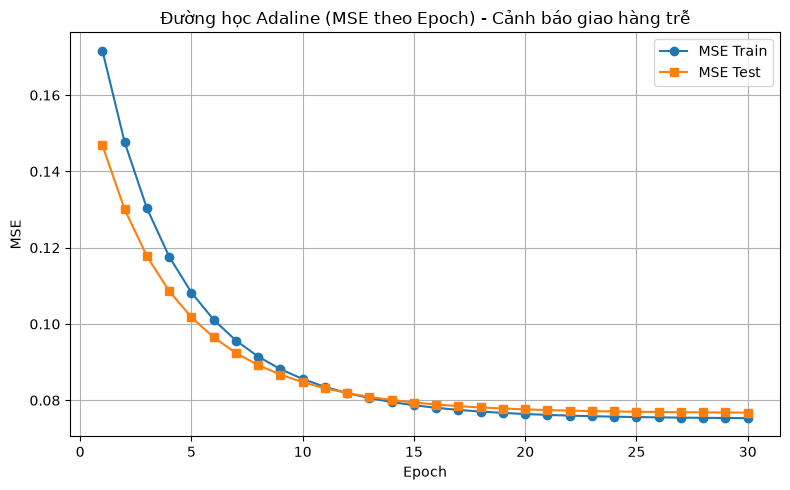

In [104]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Vẽ MSE Train và MSE Test theo Epoch
plt.plot(range(1, len(model.mse_train_) + 1), model.mse_train_, marker='o', label='MSE Train')
plt.plot(range(1, len(model.mse_val_) + 1), model.mse_val_, marker='s', label='MSE Test')

plt.title('Đường học Adaline (MSE theo Epoch) - Cảnh báo giao hàng trễ')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Ta vẽ mức sai số qua từng lần học, cho cả phần đã học lẫn phần giấu đi. Nếu đường đi xuống và ổn định thì máy đang học tốt.

Ta vẽ mức sai số qua từng lần học, cho cả phần đã học lẫn phần giấu đi. Nếu đường đi xuống và ổn định thì máy đang học tốt.

## 6. Đánh giá và phân tích

Xem lại các mẫu có sai số dự đoán lớn nhất, đọc dấu của trọng số và đối chiếu với trực giác nghiệp vụ.

In [105]:
net_test = np.dot(X_test, model.w_) + model.b_
errors_test = t_test - net_test
abs_errors_test = np.abs(errors_test)

# 1. In ra bộ trọng số w và bias b đã học được
print("=============== BẢNG TRỌNG SỐ VÀ BIAS ĐÃ HỌC ===============")
for name, w in zip(FEATURE_NAMES, model.w_):
    print(f"Trọng số {name:25s}: {w:.4f}")
print(f"Bias b                           : {model.b_:.4f}")

# 2. Liệt kê Top 3 mẫu có sai số tuyệt đối |e| lớn nhất trên tập Test
top_3_idx = np.argsort(abs_errors_test)[-3:][::-1]

print("\n=============== TOP 3 MẪU CÓ SAI SỐ |e| LỚN NHẤT =============")
for idx in top_3_idx:
    print(f"Mẫu #{idx}: Feature thô = {X_test_raw[idx]}")
    print(f"  Target thực tế t = {t_test[idx]:.4f} | Dự đoán net = {net_test[idx]:.4f} | Sai số e = {errors_test[idx]:.4f}")

=============== BẢNG TRỌNG SỐ VÀ BIAS ĐÃ HỌC ===============
Trọng số khoang_cach_km           : 0.0152
Trọng số so_don_tai_xe            : 0.1069
Trọng số troi_mua                 : 0.1197
Trọng số gio_cao_diem             : 0.1017
Trọng số thoi_gian_chuan_bi_phut  : 0.0756
Bias b                           : 0.3345

=============== TOP 3 MẪU CÓ SAI SỐ |e| LỚN NHẤT =============
Mẫu #798: Feature thô = [ 5.  7.  1.  1. 25.]
  Target thực tế t = 0.0000 | Dự đoán net = 1.1463 | Sai số e = -1.1463
Mẫu #4682: Feature thô = [1.5 0.  0.  0.  5. ]
  Target thực tế t = 1.0000 | Dự đoán net = -0.1379 | Sai số e = 1.1379
Mẫu #3551: Feature thô = [1.5 0.  0.  0.  5. ]
  Target thực tế t = 1.0000 | Dự đoán net = -0.1379 | Sai số e = 1.1379


Ta in ra mức ảnh hưởng của từng thông tin lên khả năng trễ, rồi đối chiếu với lẽ thường: xa, mưa, giờ cao điểm thì phải làm tăng nguy cơ trễ. Ta cũng xem 3 đơn mà máy đoán sai nhiều nhất để hiểu vì sao.

## 7. Chọn ngưỡng và thử nghiệm

Nếu cần một quyết định rời rạc (ví dụ cảnh báo/không cảnh báo) từ điểm liên tục, hãy chọn ngưỡng phù hợp và giải thích lựa chọn.

In [106]:
# Chọn ngưỡng quyết định (Threshold) = 0.5
# Nếu net >= 0.5 -> Đơn hàng có nguy cơ trễ cao (CẢNH BÁO TRỄ)
# Nếu net < 0.5  -> Đơn hàng nằm trong tầm kiểm soát (BÌNH THƯỜNG)
THRESHOLD = 0.5

def predict_order(record_dict, model_w, model_b, mean_vec, std_vec, threshold=0.5):
    # Lấy đặc trưng thô theo đúng thứ tự
    x_raw = np.array([record_dict[col] for col in FEATURE_NAMES], dtype=float)
    # Chuẩn hoá Z-score bằng Mean và Std của tập Train
    x_scaled = (x_raw - mean_vec) / std_vec
    # Tính điểm net liên tục: net = w^T * x + b
    net = float(np.dot(x_scaled, model_w) + model_b)
    # Đưa ra quyết định rời rạc dựa trên ngưỡng
    decision = "CẢNH BÁO TRỄ" if net >= threshold else "BÌNH THƯỜNG"
    return net, decision

# Định nghĩa 2 mẫu thử nghiệm mới
test_samples = [
    {
        "name": "Đơn hàng A (Điều kiện bất lợi: Khoảng cách xa, mưa, cao điểm)",
        "data": {
            'khoang_cach_km': 12.0,
            'so_don_tai_xe': 5,
            'troi_mua': 1,
            'gio_cao_diem': 1,
            'thoi_gian_chuan_bi_phut': 35.0
        }
    },
    {
        "name": "Đơn hàng B (Điều kiện thuận lợi: Gần, không mưa, ít đơn)",
        "data": {
            'khoang_cach_km': 2.5,
            'so_don_tai_xe': 1,
            'troi_mua': 0,
            'gio_cao_diem': 0,
            'thoi_gian_chuan_bi_phut': 10.0
        }
    }
]

print(f"=== KẾT QUẢ THỬ NGHIỆM VỚI NGƯỠNG THRESHOLD = {THRESHOLD} ===")
for sample in test_samples:
    score, result = predict_order(sample["data"], model.w_, model.b_, X_mean, X_std, THRESHOLD)
    print(f"\n[{sample['name']}]")
    print(f"-> Điểm nguy cơ (net): {score:.4f}")
    print(f"-> Quyết định        : {result}")

=== KẾT QUẢ THỬ NGHIỆM VỚI NGƯỠNG THRESHOLD = 0.5 ===

[Đơn hàng A (Điều kiện bất lợi: Khoảng cách xa, mưa, cao điểm)]
-> Điểm nguy cơ (net): 1.2070
-> Quyết định        : CẢNH BÁO TRỄ

[Đơn hàng B (Điều kiện thuận lợi: Gần, không mưa, ít đơn)]
-> Điểm nguy cơ (net): 0.0086
-> Quyết định        : BÌNH THƯỜNG


Máy cho ra một điểm. Từ 0.5 trở lên thì báo "có thể trễ", thấp hơn thì coi là bình thường. Ta thử với hai đơn mới: đơn xa 12 km, trời mưa, giờ cao điểm thì kỳ vọng bị cảnh báo. Đơn gần 2.5 km, trời đẹp, ít đơn thì kỳ vọng bình thường.

## 8. Kết luận

Adaline phù hợp vượt trội hơn Perceptron 0/1 cho bài toán này.


Lý do là nguy cơ giao trễ là một giá trị liên tục, trễ ít hay trễ nhiều rất khác nhau nên không thể ép chung thành nhãn 0/1. Perceptron dùng hàm bước nhảy khiến quá trình học bị gián đoạn. Ngược lại, Adaline đo chênh lệch liên tục và tối ưu bằng MSE giúp mô hình dự đoán chính xác điểm nguy cơ.


Giới hạn của Adaline là chỉ học được mối quan hệ tuyến tính đường thẳng.


Trong thực tế, các yếu tố như thời tiết xấu kết hợp giờ cao điểm sẽ tạo ra tắc đường tăng theo cấp số nhân. Vì vậy cần nâng cấp lên mạng MLP để xử lý các mối quan hệ phi tuyến phức tạp này.y